## 5. Data Visualisation

In [1]:
# saving/accessing files
import os
from pathlib import Path

# editing files
import geopandas as gpd
import pandas as pd
import json
import csv

# maths functions
import numpy as np

# visuals
from ipyleaflet import Map, basemaps, basemap_to_tiles
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import RegularPolygon



## Saving petitions data to variables

In [2]:
petitions_region_df = pd.read_csv("data/Top_topics_by_region.csv")
petitions_con_df = pd.read_csv("data/Top_topics_by_constituency.csv")
petitions_df = pd.read_csv("data/Top_topics.csv")

In [36]:
# lopping through each file to calculate the weighted topics. Weighted means that the topic count is weighted in context to how 
# many petitions that constituency has signed overall such that south east is not as disproportionately represented.
for i in range (16):
    # set each weighted topic count to 0 to add to later
    petitions_region_df[f"Weighted Topic {i+1}"] = 0

for i in range(len(petitions_region_df)):
    # remove non_numeric columns
    topic_interest_cols = petitions_region_df.drop(columns=['Unnamed: 0', 'Region', 'Year', 'Top Topic'])
    # sum each numeric col in that row to get overall interest for that constituency in that year
    total_regional_interest = topic_interest_cols.sum(axis=1, skipna=True)
    for j in range(16):
        # divide each topic by the overall to get each topic's score
        petitions_region_df[f"Weighted Topic {j+1}"][i] = petitions_region_df.iloc[i][f"Topic {j+1} Count"] / total_regional_interest[i]

for i in range (16):
    # set each weighted topic count to 0 to add to later
    petitions_con_df[f"Weighted Topic {i+1}"] = 0

for i in range(len(petitions_con_df)):
    # remove non_numeric columns
    topic_interest_cols = petitions_con_df.drop(columns=['Unnamed: 0', 'Constituency', 'Year', 'Top Topic'])
    # sum each numeric col in that row to get overall interest for that constituency in that year
    total_con_interest = topic_interest_cols.sum(axis=1, skipna=True)
    for j in range(16):
        # divide each topic by the overall to get each topic's score
        petitions_con_df[f"Weighted Topic {j+1}"][i] = petitions_con_df.iloc[i][f"Topic {j+1} Count"] / total_con_interest[i]

petitions_region_df.to_csv('data/Top_topics_by_region.csv')
petitions_con_df.to_csv('data/Top_topics_by_constituency.csv')


C:\Users\morriseb\AppData\Local\Temp\ipykernel_25380\3664334699.py:14: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  petitions_region_df[f"Weighted Topic {j+1}"][i] = petitions_region_df.iloc[i][f"Topic {j+1} Count"] / total_regional_interes

In [4]:
# setting up maps for heatmap
con_2015_shapefile = Path("../map_data/con_2015/WPC_Dec_2015_FCB_GB.shp")
con_2024_shapefile = Path("../map_data/con_2024/PCON_JULY_2024_UK_BFE.shp")

map_2015_df = gpd.read_file(con_2015_shapefile).rename(columns={"pcon15nm":"Constituency"})
map_2024_df = gpd.read_file(con_2024_shapefile).rename(columns={"PCON24NM":"Constituency"})

# setting up maps for hexmap
# 2015 uses file from 2010 as couldn't find data on 2015
hexjson_file_2015 = Path("../map_data/con_2015/constituencies_2010.hexjson")
hexjson_file_2024 = Path("../map_data/con_2024/uk-constituencies-2024.hexjson")

In [5]:
# filtering petitions df by year
petitions_region_2015 = petitions_region_df[petitions_region_df["Year"]==2015]
petitions_region_2016 = petitions_region_df[petitions_region_df["Year"]==2016]
petitions_region_2017 = petitions_region_df[petitions_region_df["Year"]==2017]
petitions_region_2018 = petitions_region_df[petitions_region_df["Year"]==2018]
petitions_region_2019 = petitions_region_df[petitions_region_df["Year"]==2019]
petitions_region_2020 = petitions_region_df[petitions_region_df["Year"]==2020]
petitions_region_2021 = petitions_region_df[petitions_region_df["Year"]==2021]
petitions_region_2022 = petitions_region_df[petitions_region_df["Year"]==2022]
petitions_region_2023 = petitions_region_df[petitions_region_df["Year"]==2023]
petitions_region_2024 = petitions_region_df[petitions_region_df["Year"]==2024]
petitions_region_2025 = petitions_region_df[petitions_region_df["Year"]==2025]

# filtering petitions df by year
petitions_con_2015 = petitions_con_df[petitions_con_df["Year"]==2015]
petitions_con_2016 = petitions_con_df[petitions_con_df["Year"]==2016]
petitions_con_2017 = petitions_con_df[petitions_con_df["Year"]==2017]
petitions_con_2018 = petitions_con_df[petitions_con_df["Year"]==2018]
petitions_con_2019 = petitions_con_df[petitions_con_df["Year"]==2019]
petitions_con_2020 = petitions_con_df[petitions_con_df["Year"]==2020]
petitions_con_2021 = petitions_con_df[petitions_con_df["Year"]==2021]
petitions_con_2022 = petitions_con_df[petitions_con_df["Year"]==2022]
petitions_con_2023 = petitions_con_df[petitions_con_df["Year"]==2023]
petitions_con_2024 = petitions_con_df[petitions_con_df["Year"]==2024]
petitions_con_2025 = petitions_con_df[petitions_con_df["Year"]==2025]

In [6]:
# importing data to construct a hex map and convert to csv file
def convert_hex_csv(file):
    """ 
    function to convert hexjson files to a dataframe that can be saved as csv
    :input file: the hexjson file to be converted
    :output: dataframe with the hexjson file information
    """
    # setting up the columns for a dataframe
    map_df = pd.DataFrame(columns=["Constituency", "q", "r"])

    # opening the json file and loading hex values
    with open(file, "r", encoding="utf8") as json_file:
        hex = json.load(json_file)["hexes"]
    # for each item in hexes column, saving to dictionary as seperate components
    for _, values in hex.items():
        data = {
                "Constituency": values["n"],
                "q": values["q"],
                "r": values["r"]
            }
        # appending to end of dataframe
        map_df.loc[len(map_df)] = data
    
    return map_df

In [7]:
# applying hex conversion
map_2015_df = convert_hex_csv(hexjson_file_2015)
map_2024_df = convert_hex_csv(hexjson_file_2024)

# saving
map_2015_df.to_csv("../map_data/con_2015/uk_hex_2015.csv")
map_2024_df.to_csv("../map_data/con_2024/uk_hex_2024.csv")

# unsorted files leed to issues later when merging with petitions_df so sorting by constituency
map_2015_df = map_2015_df.sort_values(by="Constituency")
map_2024_df = map_2024_df.sort_values(by="Constituency")

In [8]:
# region boundaries have less change to borders and so have just chosen the 2018 file from ONS and changed the region 
# named 'Eastern' to 'East of England' to match petition files
region_shapefile = Path("../map_data/regions/European_Electoral_Regions_Dec_2018_FCB_UK.shp")
map_regions_df = gpd.read_file(region_shapefile).rename(columns={"eer18nm":"Region"})
map_regions_df.loc[map_regions_df['Region'] == "Eastern", 'Region'] = "East of England"

In [9]:
# combining petition data with map data
combined_region_2015 = map_regions_df.set_index("Region").join(petitions_region_2015.set_index("Region")).reset_index()
combined_region_2016 = map_regions_df.set_index("Region").join(petitions_region_2016.set_index("Region")).reset_index()
combined_region_2017 = map_regions_df.set_index("Region").join(petitions_region_2017.set_index("Region")).reset_index()
combined_region_2018 = map_regions_df.set_index("Region").join(petitions_region_2018.set_index("Region")).reset_index()
combined_region_2019 = map_regions_df.set_index("Region").join(petitions_region_2019.set_index("Region")).reset_index()
combined_region_2020 = map_regions_df.set_index("Region").join(petitions_region_2020.set_index("Region")).reset_index()
combined_region_2021 = map_regions_df.set_index("Region").join(petitions_region_2021.set_index("Region")).reset_index()
combined_region_2022 = map_regions_df.set_index("Region").join(petitions_region_2022.set_index("Region")).reset_index()
combined_region_2023 = map_regions_df.set_index("Region").join(petitions_region_2023.set_index("Region")).reset_index()
combined_region_2024 = map_regions_df.set_index("Region").join(petitions_region_2024.set_index("Region")).reset_index()
combined_region_2025 = map_regions_df.set_index("Region").join(petitions_region_2025.set_index("Region")).reset_index()

combined_con_2015 = map_2015_df.set_index("Constituency").join(petitions_con_2015.set_index("Constituency")).reset_index()
combined_con_2016 = map_2015_df.set_index("Constituency").join(petitions_con_2016.set_index("Constituency")).reset_index()
combined_con_2017 = map_2015_df.set_index("Constituency").join(petitions_con_2017.set_index("Constituency")).reset_index()
combined_con_2018 = map_2015_df.set_index("Constituency").join(petitions_con_2018.set_index("Constituency")).reset_index()
combined_con_2019 = map_2015_df.set_index("Constituency").join(petitions_con_2019.set_index("Constituency")).reset_index()
combined_con_2020 = map_2015_df.set_index("Constituency").join(petitions_con_2020.set_index("Constituency")).reset_index()
combined_con_2021 = map_2015_df.set_index("Constituency").join(petitions_con_2021.set_index("Constituency")).reset_index()
combined_con_2022 = map_2015_df.set_index("Constituency").join(petitions_con_2022.set_index("Constituency")).reset_index()
combined_con_2023 = map_2015_df.set_index("Constituency").join(petitions_con_2023.set_index("Constituency")).reset_index()
combined_con_2024 = map_2024_df.set_index("Constituency").join(petitions_con_2024.set_index("Constituency")).reset_index()
combined_con_2025 = map_2024_df.set_index("Constituency").join(petitions_con_2025.set_index("Constituency")).reset_index()

In [10]:
def top_three(file, year):    
    """ 
    Finds the top three weighted topics and returns the column names to plot those columns
    :param file: dataframe of constituency with weighted topic interest
    :param year: integer from 2015-2025
    :output: list of column names as string which can be plotted
    """
    # filter file by
    filtered_file = file[file['Year']==year]

    # empty list of columns to be added to
    columns_to_plot = []

    # looping through petiitons to fin
    for i in range(len(filtered_file)):
        # empty list to be added to for each topic
        sig_count = []
        for col in range(20, 37):
            # looping through weighted topics and adding score to sig_count
            sig_count.append(filtered_file.iloc[i, col])
        # ordering signatures and then using the values to find the most significant topics
        ordered_sig_count = sorted(sig_count, reverse=True)

        columns_to_plot.append("Weighted Topic " + str(sig_count.index(ordered_sig_count[0])+1))
        columns_to_plot.append("Weighted Topic " + str(sig_count.index(ordered_sig_count[1])+1))
        columns_to_plot.append("Weighted Topic " + str(sig_count.index(ordered_sig_count[2])+1))

    return columns_to_plot

In [11]:
def top_constituencies(file, topic):
    """ 
    Finds the top constituencies for a given topic and returns the top 5
    :param file: given petitions file for that year/area
    :param topic: string with the column name for the topic regarded e.g. 'Weighted Topic 5'
    :output: list of 5 constituency names
    """
    # sort file by column
    file = file.sort_values(by=topic, ascending=False)
    # find top 5 values
    constituencies = file['Constituency'][0:5].values
    
    return constituencies


## Topic interest by region

In [12]:
# List of columns you want to plot - chosen based on top topics by year, restricted for now for topics between 2017-2022
# total_columns = []
# for year in range(2021, 2026):
#     columns_to_plot = top_three(petitions_df, year)
#     total_columns.append(columns_to_plot)
# no longer using this as narrowing to just 5 topics that are analysed further

In [13]:

def plot_map_by_year(columns, titles, filtered_parl_file, topic, fig_text, n_cols=3):
    """ 
    Function to plot signature counts over the UK heatmap for given year. 
    :param columns: list of names of columns to plot
    :param titles: titles of each plot (names of topics)
    :param filtered_parl_file: dataframe filtered by parliament
    :param year: integer indicating year for data for suptitle
    :param fig_text: text string to indicate text for figure labelling
    """
    # Determine subplot layout
    n_cols = n_cols  
    n_rows = 1

    if n_cols == 1:
        # Create subplots
        fig, ax = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
        # plot the heatmap
        filtered_parl_file.plot(column=columns[0], cmap="OrRd", linewidth=0.8, ax=ax, legend=True)
        ax.set_title(titles[0], fontsize=25)
        ax.axis("off")
        # set title and subtitle
        plot_title = "Heatmap of interest in " + topic
        plt.suptitle(plot_title, fontsize=30, fontweight='bold')
        plt.figtext(0.5, -0.05, fig_text, ha="center", fontsize=15)
    else:
        # Create subplots
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
        # Plot each column
        for i, column in enumerate(columns):
            ax = axes[i]
            filtered_parl_file.plot(column=column, cmap="OrRd", linewidth=0.8, ax=ax, legend=True)
            ax.set_title(titles[i], fontsize=25)
            ax.axis("off")

        # Hide any unused subplots
        for j in range(i + 1, len(axes)):
            axes[j].axis("off")    

        plot_title = "Heatmap of interest in " + topic
        plt.suptitle(plot_title, fontsize=30, fontweight='bold')
        plt.figtext(0.5, -0.05, fig_text, ha="center", fontsize=15)
    plt.tight_layout()
    plt.show()



## Covid topics 2020-2021

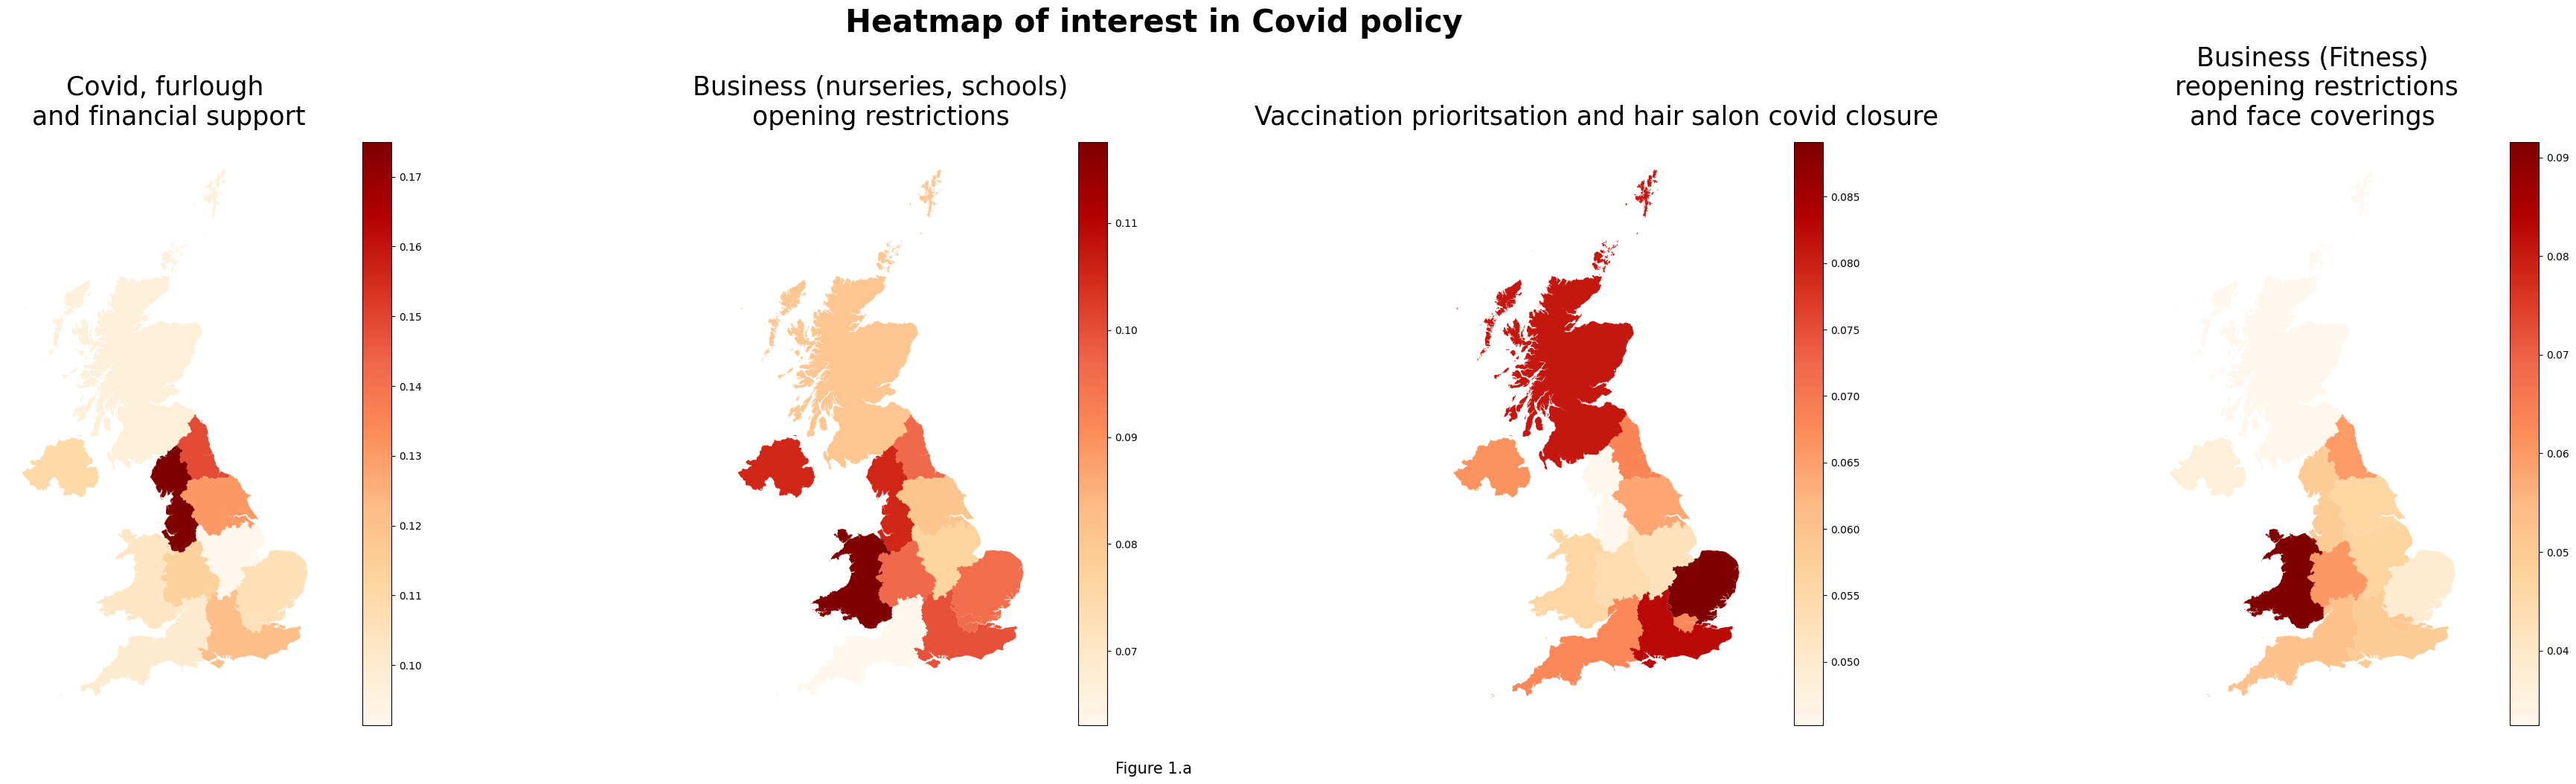

In [14]:
titles = ["Covid, furlough\n and financial support", "Business (nurseries, schools)\nopening restrictions", "Vaccination prioritsation and hair salon covid closure", 
          "Business (Fitness)\n reopening restrictions\nand face coverings"]
plot_map_by_year(["Weighted Topic 14", "Weighted Topic 13", "Weighted Topic 6", "Weighted Topic 12"],  titles, combined_region_2020, "Covid policy", "Figure 1.a", 4)

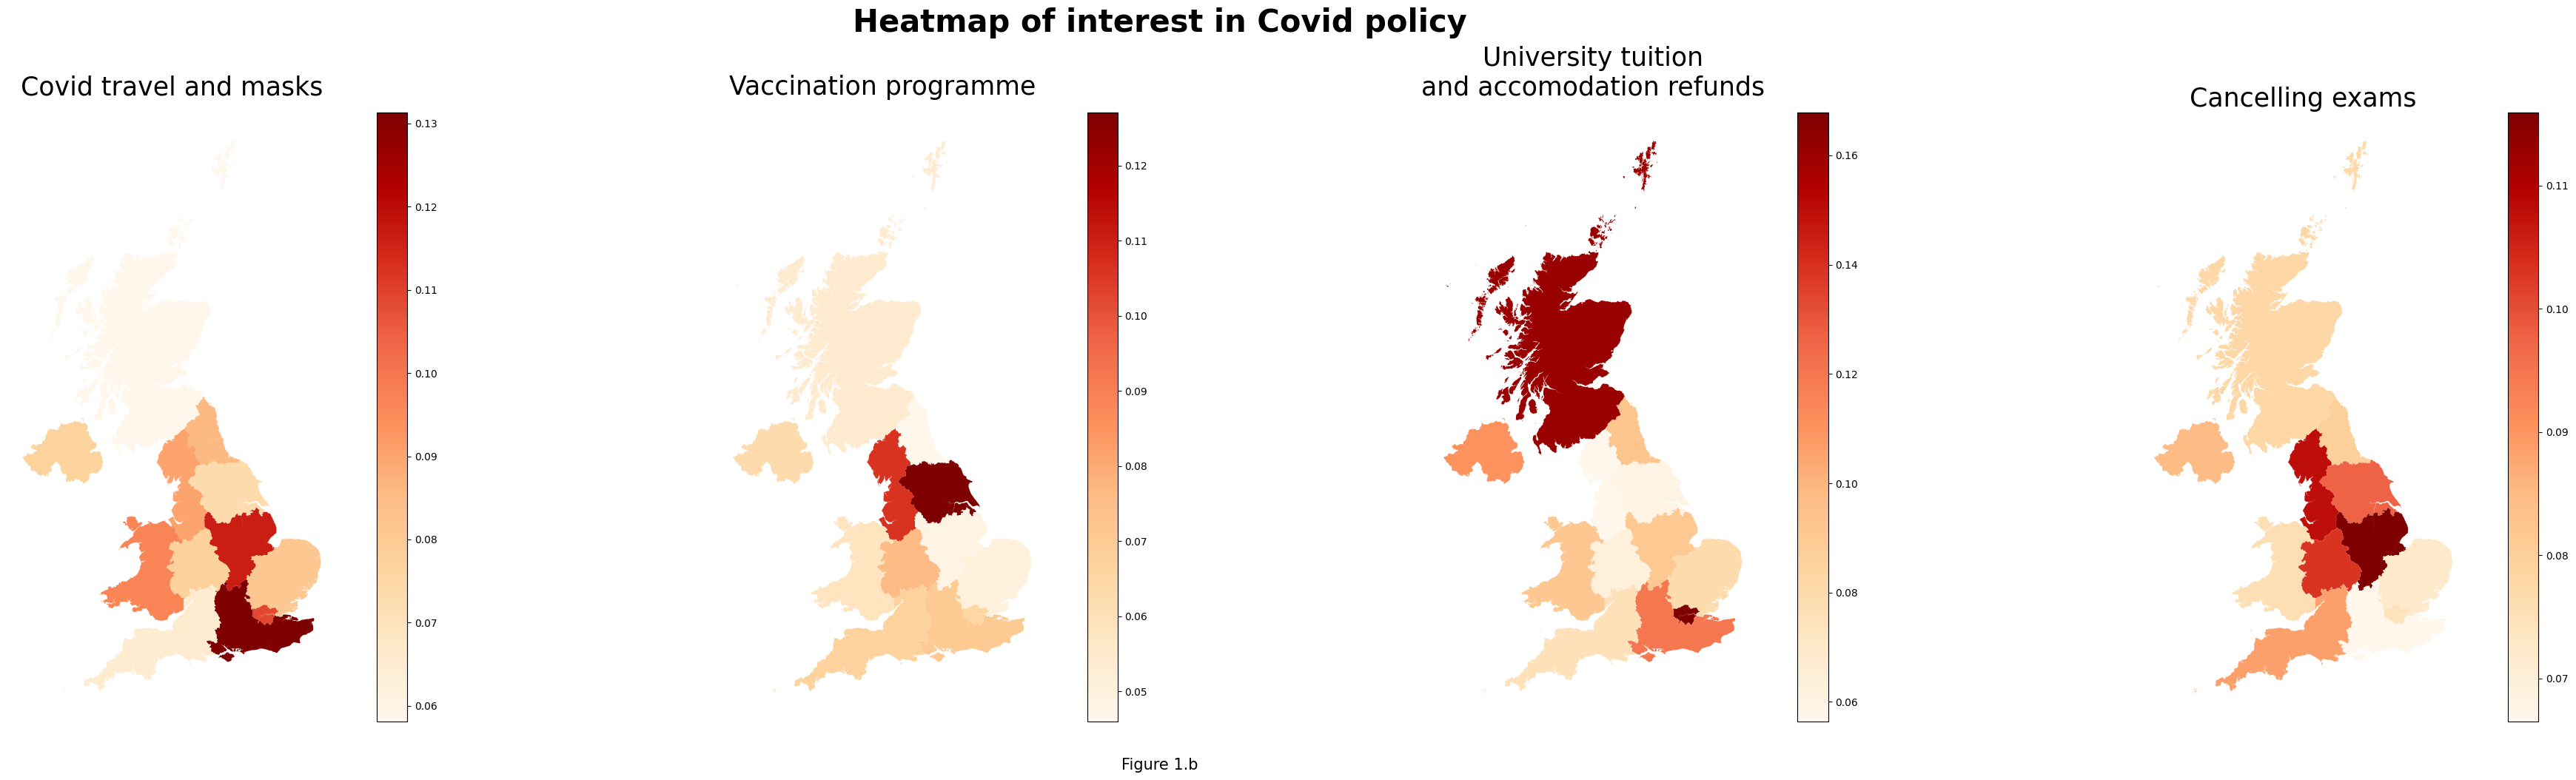

In [15]:
titles = ["Covid travel and masks", "Vaccination programme", "University tuition\nand accomodation refunds", "Cancelling exams"]
plot_map_by_year(["Weighted Topic 10", "Weighted Topic 15", "Weighted Topic 9", "Weighted Topic 2"],  titles, combined_region_2021, "Covid policy", "Figure 1.b", 4)

## Environmental topics 2023-2024 
(some petitions in 2022 and 2025 of note but generally categorised in misc as there are less petitions from that theme)

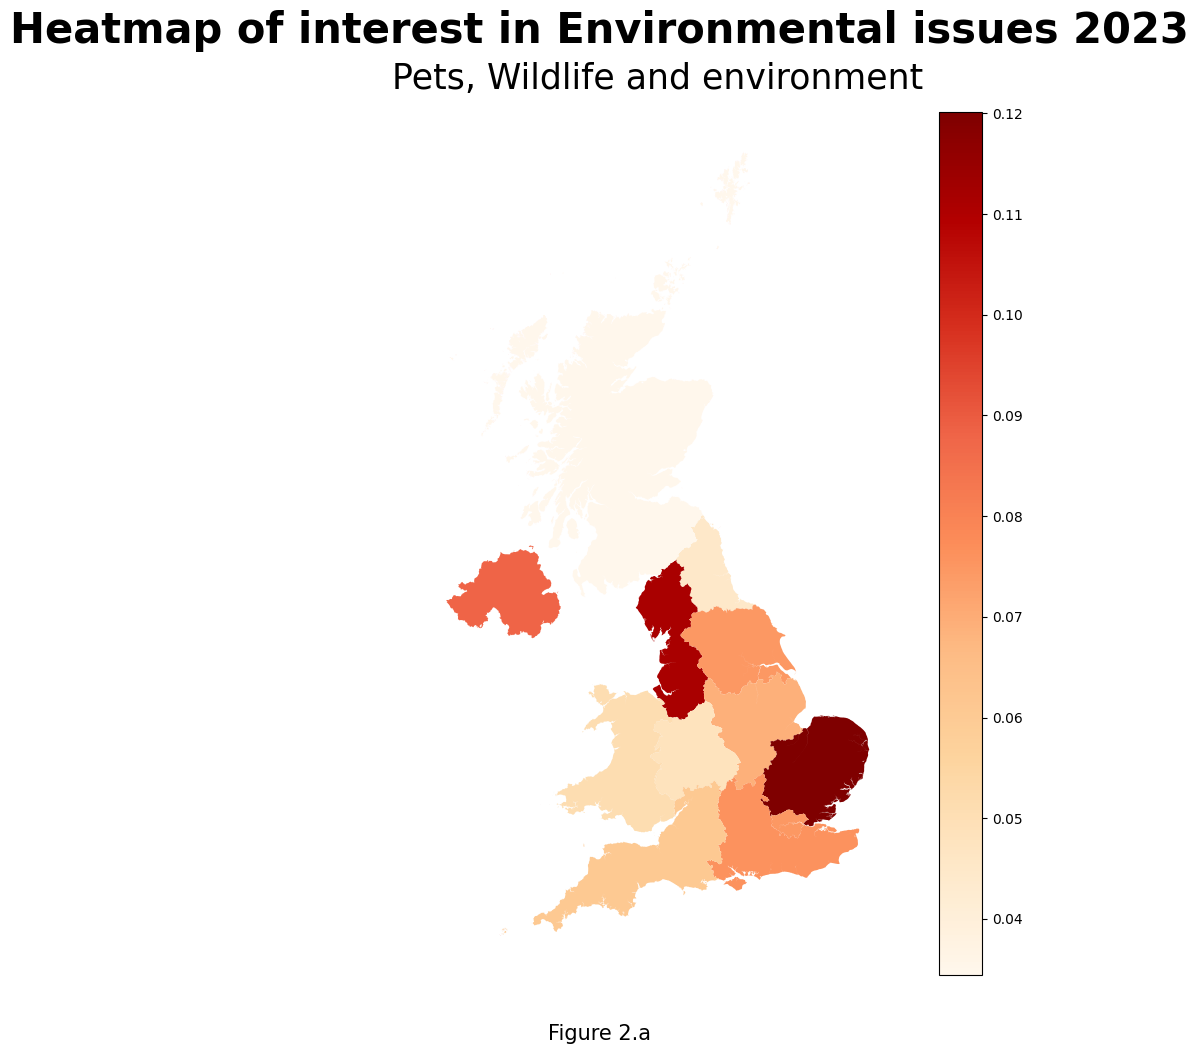

In [16]:
titles =  ["Pets, Wildlife and environment"] 

plot_map_by_year(["Weighted Topic 5"], titles, combined_region_2023, "Environmental issues 2023", "Figure 2.a", 1)

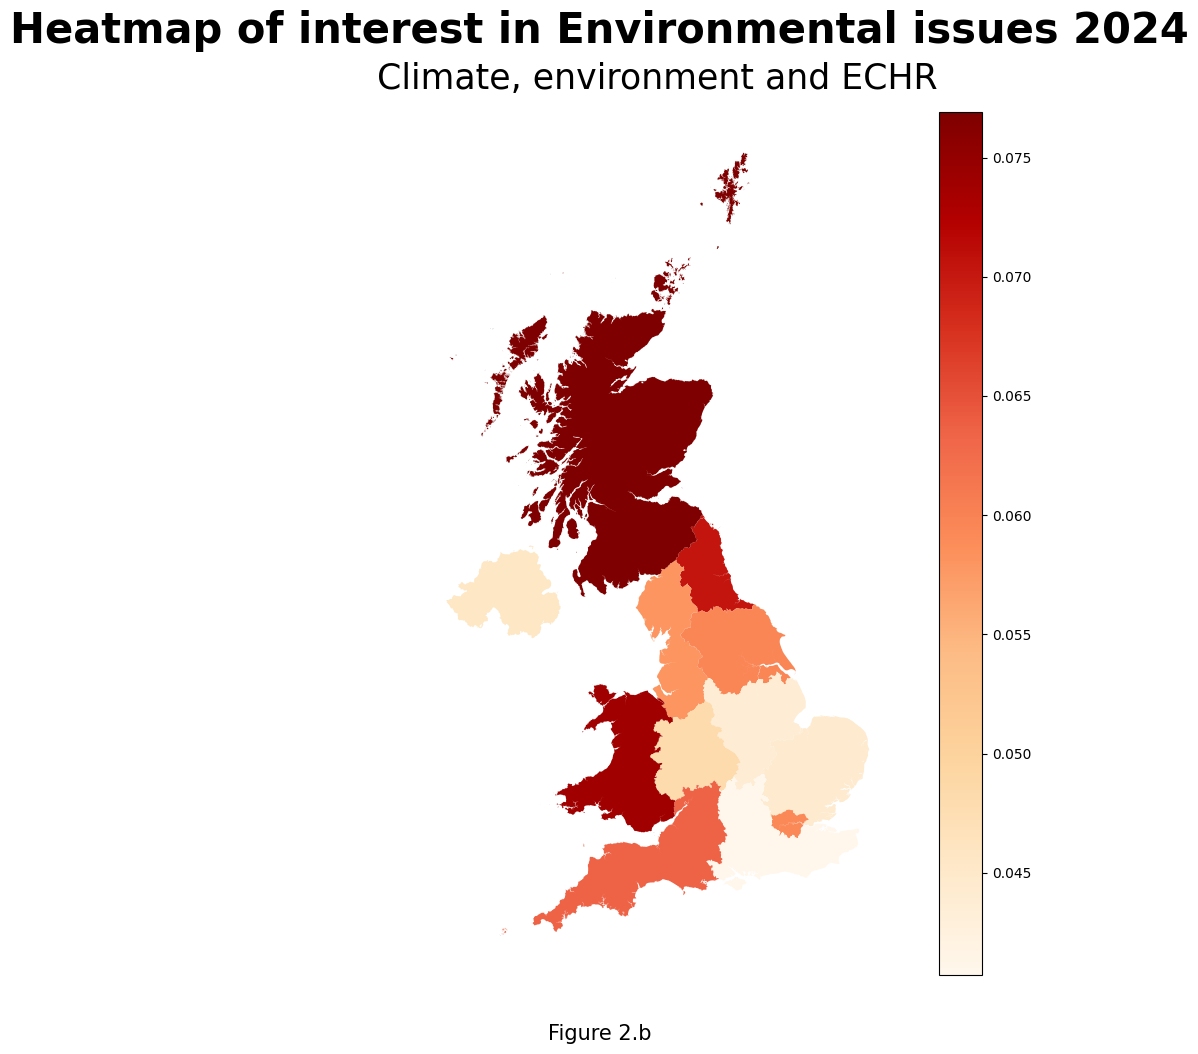

In [17]:
titles =  ["Climate, environment and ECHR"] 

plot_map_by_year(["Weighted Topic 16"], titles, combined_region_2024, "Environmental issues 2024", "Figure 2.b", 1)

## Crime patterns

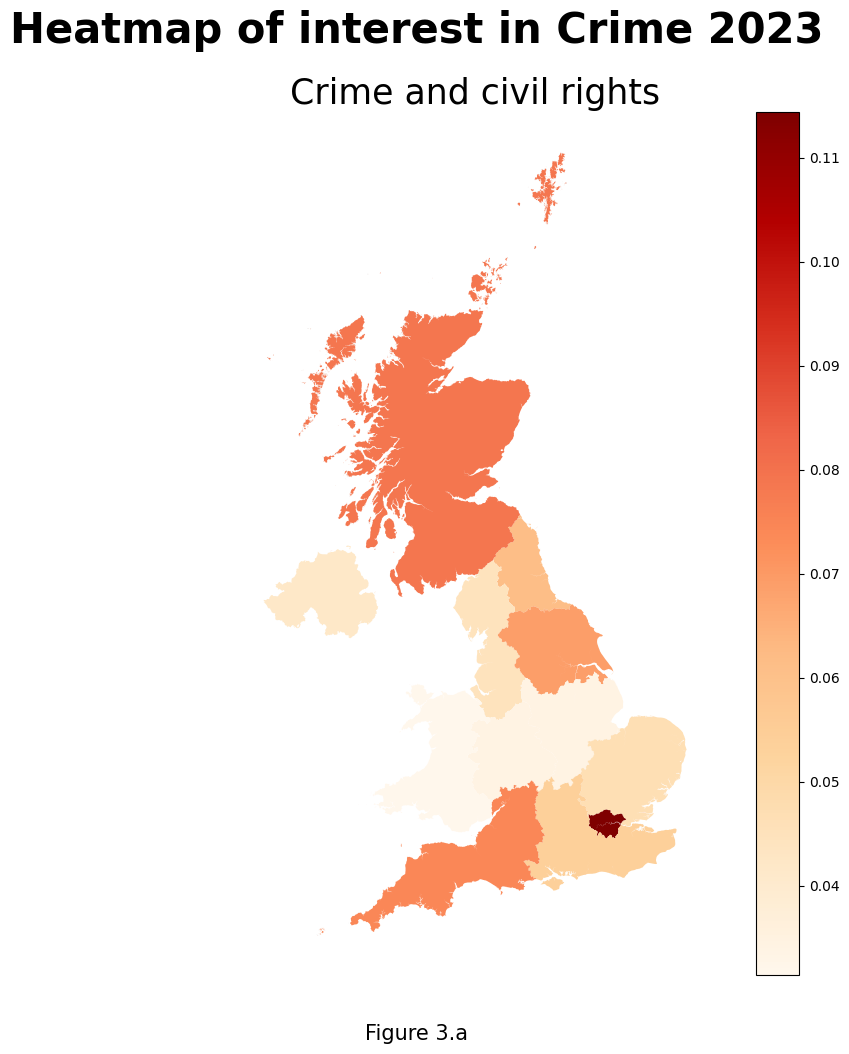

In [18]:
titles =  ["Crime and civil rights"] 

plot_map_by_year(["Weighted Topic 2"], titles, combined_region_2023, "Crime 2023", "Figure 3.a", 1)

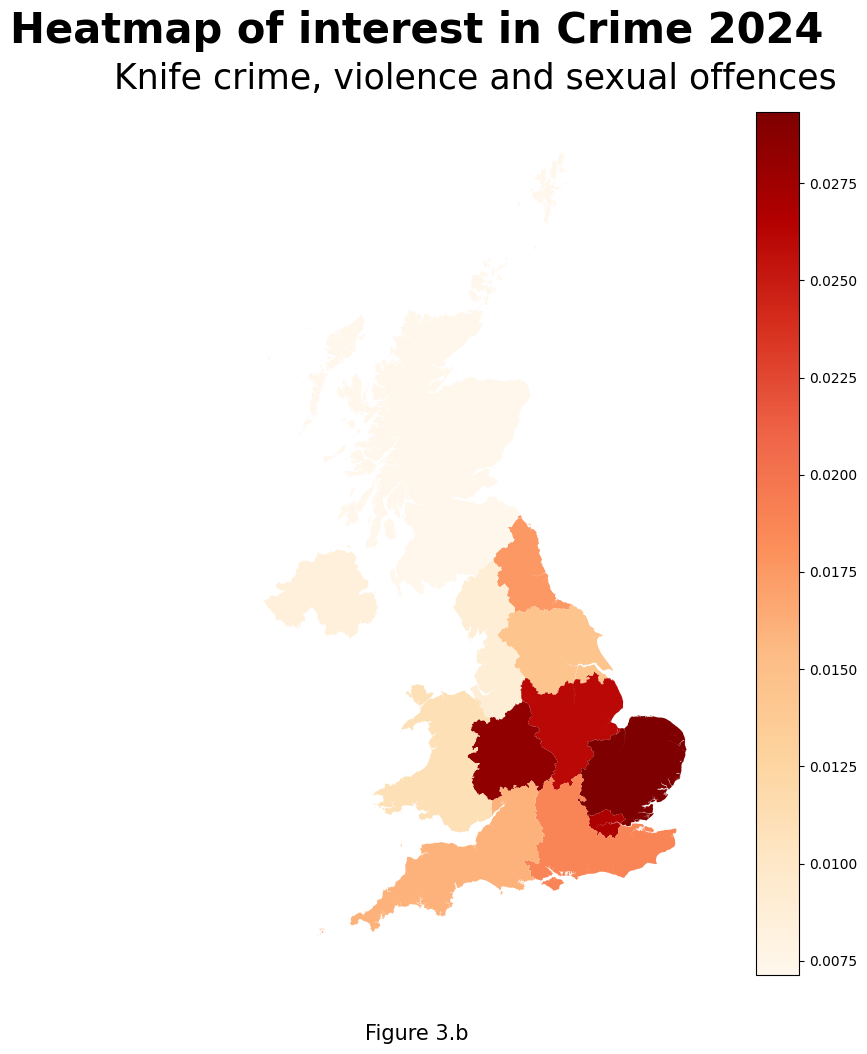

In [19]:
titles =  ["Knife crime, violence and sexual offences"] 

plot_map_by_year(["Weighted Topic 11"], titles, combined_region_2024, "Crime 2024", "Figure 3.b", 1)

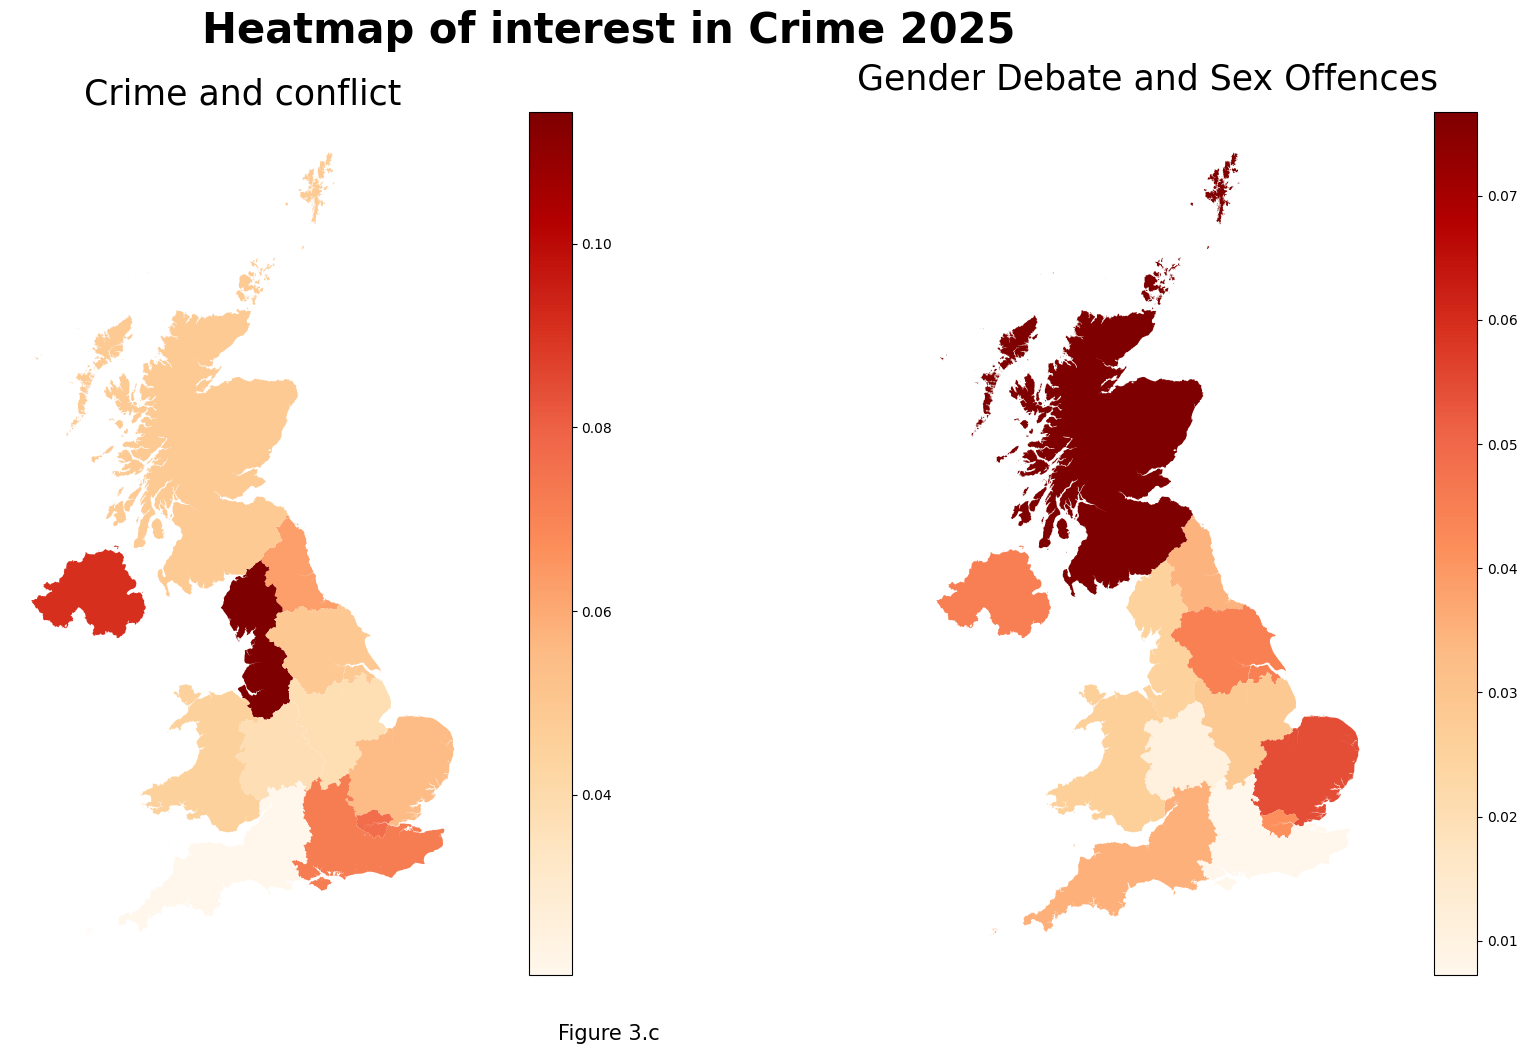

In [20]:
titles =  ["Crime and conflict", "Gender Debate and Sex Offences"] 

plot_map_by_year(["Weighted Topic 1", "Weighted Topic 5"], titles, combined_region_2025, "Crime 2025", "Figure 3.c", 2)

## Topic interest by constituency

In [21]:
class HexMap:
    """
    HexMap creates a map by drawing equally sized polygons.
    These maps are useful to visualise election results, as
    metropolitan areas can often distort how many people are
    voting a certain way.
    """

    def __init__(self):
        self._map_df = None
        self._map_fig = None
        self._output_loc = None
        self._columns_to_plot = None
        self._orientation = "odd-r"

    def load_map(self, hexmap, is_path=True, columns_to_plot=None, **kwargs):
        """
        Load the hex map
        :param hexmap: the filename of the map to load or the dataframe itself
        :param is_path: optional bool. If True, then hexmap is a path to the map csv.
                        Else it's a dataframe
        :param value_column: optional string. The name of the column in the csv
        """
        if is_path:
            hexmap = pd.read_csv(hexmap, **kwargs)
        cols = hexmap.columns
        for required_col in ("q", "r", "Constituency"):
            if required_col not in cols:
                raise RuntimeError(
                    "{} is not a column in the map dataframe. "
                    "Columns are {}.".format(required_col, cols)
                )
        self._map_df = hexmap

        if columns_to_plot is not None:
            self._columns_to_plot = columns_to_plot

    def add_data(self, data, map_join, data_join, is_path=True, **kwargs):
        """
        Add an extra dataframe to the hexmap dataframe.
        This can be used if the map dataframe contains the boundary information only,
        and you wish to add the variable which determines map colouring.
        :param data: Path to the additional dataframe, or the dataframe itself
        :param map_join: The column name in the map dataframe around which the data
                        should be joined
        :param data_join: The column name in the data dataframe around which the data
                        should be joined
        :param is_path: optional bool. If True, data is a path, else it's a dataframe
        """
        if self._map_df is None:
            raise RuntimeError("You should load a map first.")

        if is_path:
            data = pd.read_csv(data, **kwargs)

        self._map_df = (
            self._map_df.set_index(map_join)
            .join(data.set_index(data_join))
            .reset_index()
        )

    def draw_map(
        self,
        fig=None,
        _cmap="viridis",
        v_min=None,
        v_max=None,
        titles=None,
        title_kwargs=None
    ):
        """
        Create the map.
        :param fig: optional matplotlib fig object. If not provided, one is created.
        :param _cmap: optional string. Colormap to use in the plot. Default is viridis.
        :param v_min: optional float. The minimum value for the colormap.
                      If not provided, and a value column is, it's taken as
                      minimum value in the dataframe.
        :param v_max: optional float. The maximum value for the colormap.
                      If not provided, and a value column is, it's taken as
                      maximum value in the dataframe.
        :param title: optional string. Title to the figure
        :param title_kwargs: optional dict. Kwargs to the title
        :return: a matplotlib figure with the hex map drawn onto it.
        """
        if fig is None:
            # Determine subplot layout
            n_cols = len(self._columns_to_plot)  # Number of columns in subplot grid
            n_rows = 1

            # Create subplots
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
        else:
            ax = fig.axes[0]
            
        if self._columns_to_plot is not None:
            if n_cols == 1:
                ax = axes
                ax.axis("off")

                column = self._columns_to_plot[0]

                y_min = 1000
                y_max = -1000

                # TODO allow other hex orientations. We assume odd-r here.
                d = 0.5 / np.sin(np.pi / 3)
                y_diff = np.sqrt(1 - 0.5 ** 2)
                patches = []
                colours = []
                for j in range(self._map_df.shape[0]):
                    r = self._map_df.loc[j, "r"]
                    q = self._map_df.loc[j, "q"]
                    c = self._map_df.loc[j, column]

                    if r % 2 == 1:
                        # if in an odd row, we need to shift right
                        q = q + 0.5
                    r = y_diff * r
                    hexagon = RegularPolygon((q, r), numVertices=6, radius=d, edgecolor="k")
                    patches.append(hexagon)
                    colours.append(c)

                    # Get plot limits
                    if r < y_min:
                        y_min = r - 1.0
                    if r > y_max:
                        y_max = r + 1.0

                x_min = self._map_df["q"].min() - 1.0
                x_max = self._map_df["q"].max() + 1.0

                _cmap = _cmap if column is not None else None
                p = PatchCollection(patches, cmap=plt.get_cmap(_cmap), alpha=1.0)
                p.set_array(np.array(colours))

                    # Set colorbar limits
                if v_min is None:
                    v_min = self._map_df[column].min()
                if v_max is None:
                    v_max = self._map_df[column].max()

                    p.set_clim([v_min, v_max])
                    plt.colorbar(mappable=p, ax=axes, shrink=0.5)

                ax.add_collection(p)

                ax.set_xlim([x_min, x_max])
                ax.set_ylim([y_min, y_max])

                if titles is not None:
                    ax.set_title(titles[0], fontdict=title_kwargs)

            else:

                for i, column in enumerate(self._columns_to_plot):
                    ax = axes[i]
                    ax.axis("off")
                    
                    y_min = 1000
                    y_max = -1000

                    # TODO allow other hex orientations. We assume odd-r here.
                    d = 0.5 / np.sin(np.pi / 3)
                    y_diff = np.sqrt(1 - 0.5 ** 2)
                    patches = []
                    colours = []
                    for j in range(self._map_df.shape[0]):
                        r = self._map_df.loc[j, "r"]
                        q = self._map_df.loc[j, "q"]
                        c = self._map_df.loc[j, column]

                        if r % 2 == 1:
                            # if in an odd row, we need to shift right
                            q = q + 0.5
                        r = y_diff * r
                        hexagon = RegularPolygon((q, r), numVertices=6, radius=d, edgecolor="k")
                        patches.append(hexagon)
                        colours.append(c)

                        # Get plot limits
                        if r < y_min:
                            y_min = r - 1.0
                        if r > y_max:
                            y_max = r + 1.0

                    x_min = self._map_df["q"].min() - 1.0
                    x_max = self._map_df["q"].max() + 1.0

                    _cmap = _cmap if column is not None else None
                    p = PatchCollection(patches, cmap=plt.get_cmap(_cmap), alpha=1.0)
                    p.set_array(np.array(colours))

                        # Set colorbar limits
                    if v_min is None:
                        v_min = self._map_df[column].min()
                    if v_max is None:
                        v_max = self._map_df[column].max()

                        p.set_clim([v_min, v_max])
                        plt.colorbar(mappable=p, ax=axes[n_cols-1], shrink=0.5)

                    ax.add_collection(p)

                    ax.set_xlim([x_min, x_max])
                    ax.set_ylim([y_min, y_max])

                    if titles is not None:
                        ax.set_title(titles[i], fontdict=title_kwargs)

        self._map_fig = fig
        return fig

    def save_map(self, save_name, save_dir=None, **kwargs):
        """
        Save the figure
        :param save_name: the base name under which the map should be saved.
                          E.g. "myMap.png".
                          This is combined with the objects save_directory
                          to create a full save path.
        :param save_dir: optional string.
                         Directory in which to save the figure
        """
        if self._map_fig is None:
            raise RuntimeError(
                "You need to draw the map before attempting " "to save the figure."
            )

        # Update the object's save directory
        if save_dir is not None:
            self.save_directory = save_dir

        if self.save_directory is not None:
            save_name = os.path.join(self.save_directory, save_name)

        self._map_fig.savefig(save_name, **kwargs)

    def annotate_map(self, annotation, **kwargs):
        """
        Annotate the map
        :param annotation: The text to add to the figure
        :return: matplotlib figure of the map including the annotation
        """
        if self._map_fig is None:
            raise RuntimeError("Draw the map before adding an annotation to it.")

        ax = self._map_fig.axes[0]
        ax.annotate(annotation, **kwargs)

        return self._map_fig

    @property
    def columns_to_plot(self):
        return self._columns_to_plot

    @columns_to_plot.setter
    def columns_to_plot(self, _new_col):
        if self._map_df is None:
            raise RuntimeError("You should load a map before setting the columns.")

        if _new_col not in self._map_df.columns:
            raise KeyError(
                "Value column {} is not in the map dataframe. "
                "Columns are {}.".format(_new_col, self._map_df.columns)
            )
        else:
            self._columns_to_plot = _new_col

    @property
    def save_directory(self):
        return self._output_loc

    @save_directory.setter
    def save_directory(self, new_dir):
        if not os.path.exists(new_dir):
            os.mkdir(new_dir)
        self._output_loc = new_dir

    @property
    def orientation(self):
        return self._orientation

    @orientation.setter
    def orientation(self, new_orientation):
        new_orientation = new_orientation.lower()
        if new_orientation == "odd-r":
            self._orientation = new_orientation
        elif new_orientation in ("even-r", "odd-l", "even-l"):
            raise NotImplementedError(
                "{} has not yet been implemented".format(new_orientation)
            )
        else:
            raise KeyError(
                "{} is not a recognised orientation.".format(new_orientation)
            )

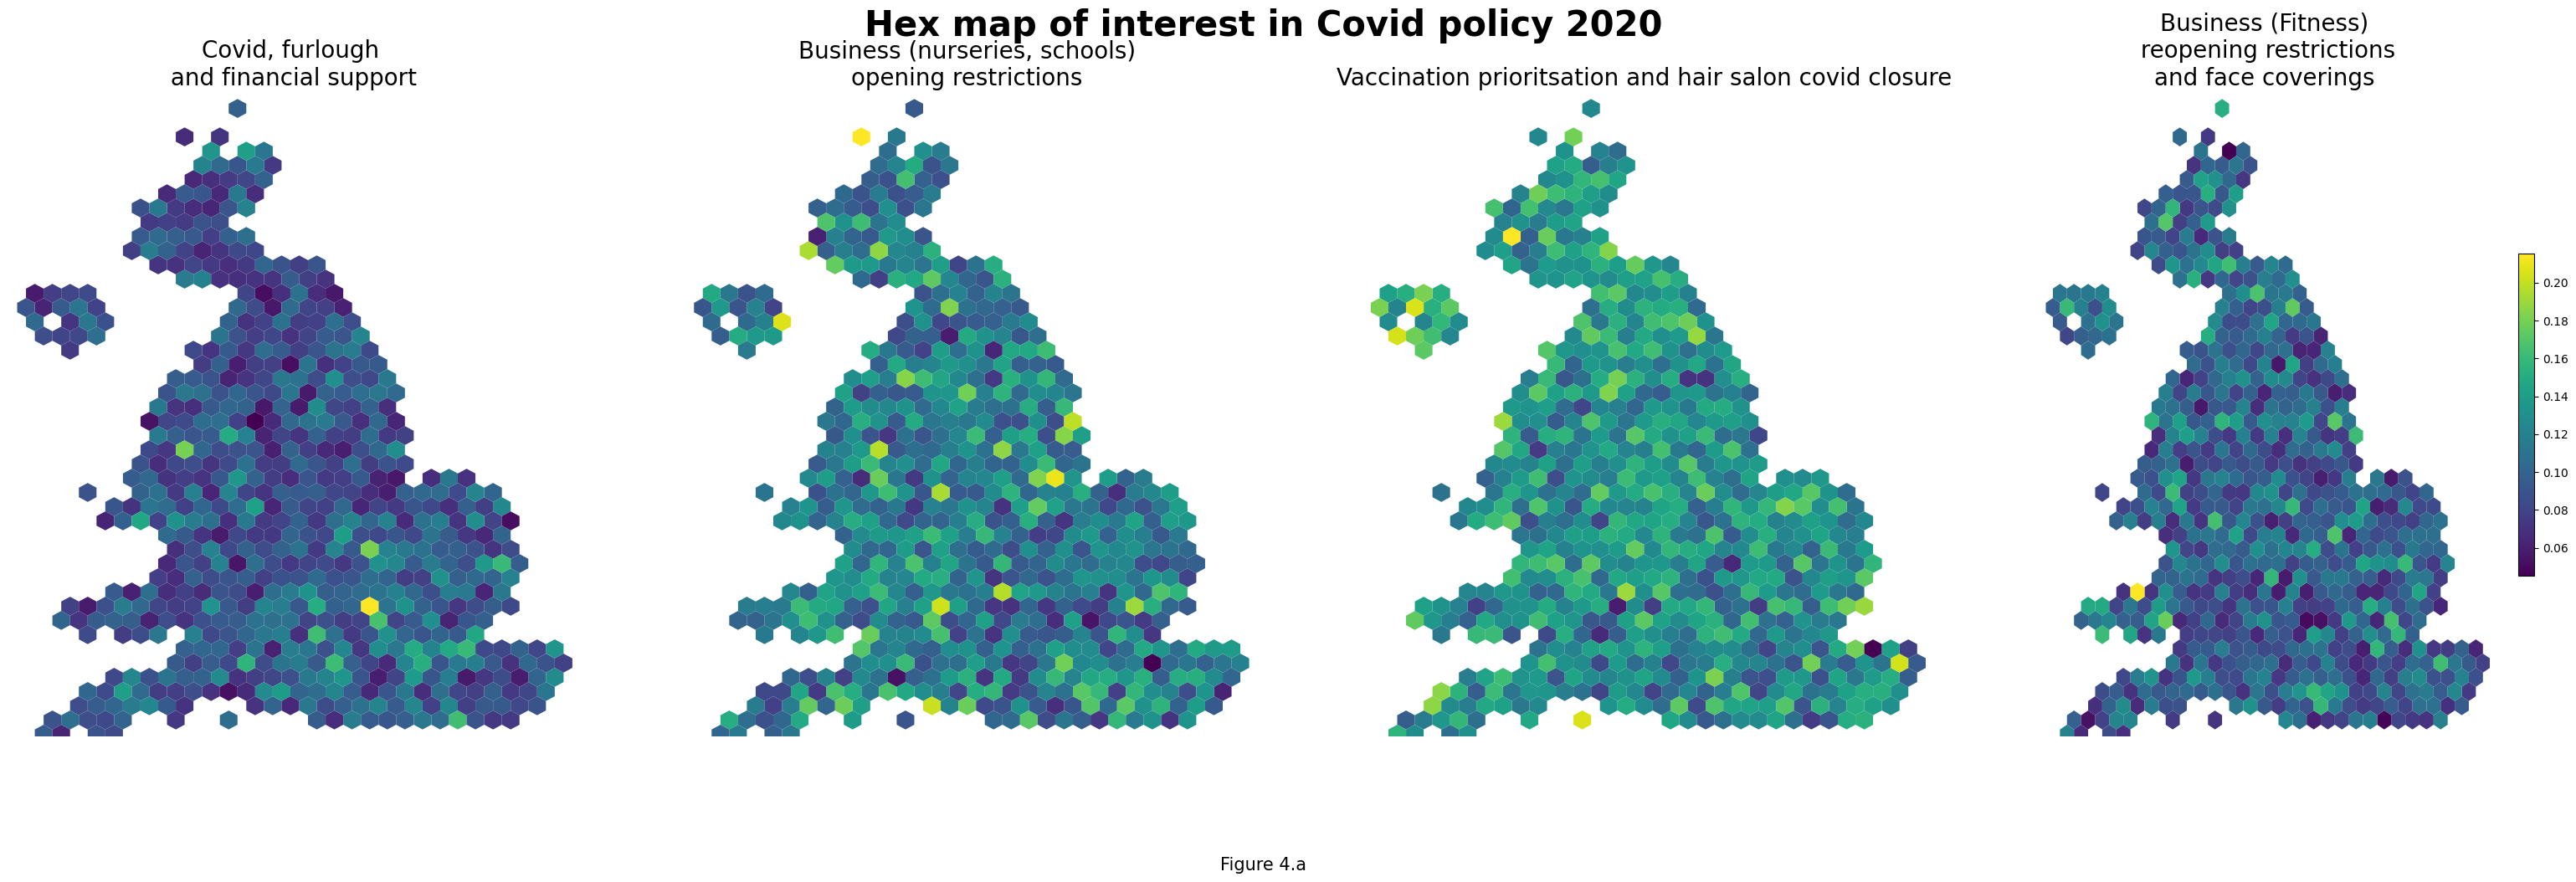

In [22]:
# set titles of topics to be investigated
titles = ["Covid, furlough\n and financial support", "Business (nurseries, schools)\nopening restrictions", "Vaccination prioritsation and hair salon covid closure", 
          "Business (Fitness)\n reopening restrictions\nand face coverings"]

# instantiate and load the hexmap
hexmapper = HexMap()
hexmapper.load_map(combined_con_2020, is_path=False, columns_to_plot=["Weighted Topic 14", "Weighted Topic 13", "Weighted Topic 6", "Weighted Topic 12"])

# Setting dictionary for font parameters
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in Covid policy 2020", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 4.a", ha="center", fontsize=15)
plt.show()

# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_covid_2020.png", save_dir=save_dir, dpi=300)

In [23]:
# checking top constituencies
con_1= top_constituencies(petitions_con_2020, "Weighted Topic 14")
con_2 = top_constituencies(petitions_con_2020, "Weighted Topic 13")
con_3 = top_constituencies(petitions_con_2020, "Weighted Topic 6")
con_4 = top_constituencies(petitions_con_2020, "Weighted Topic 12")
print("Top constituencies for each topic: ", con_1, con_2, con_3, con_4)

Top constituencies for each topic:  ['Hendon' 'Northampton South' 'Warrington North'
 'Finchley and Golders Green' 'Hayes and Harlington'] ['Na h-Eileanan an Iar' 'Gedling' 'Strangford' 'Newbury' 'Fareham'] ['Glasgow South West' 'Isle of Wight' 'South Antrim' 'Upper Bann'
 'Faversham and Mid Kent'] ['Rhondda' 'Cardiff Central' 'Easington' 'Great Grimsby' 'Glasgow North']


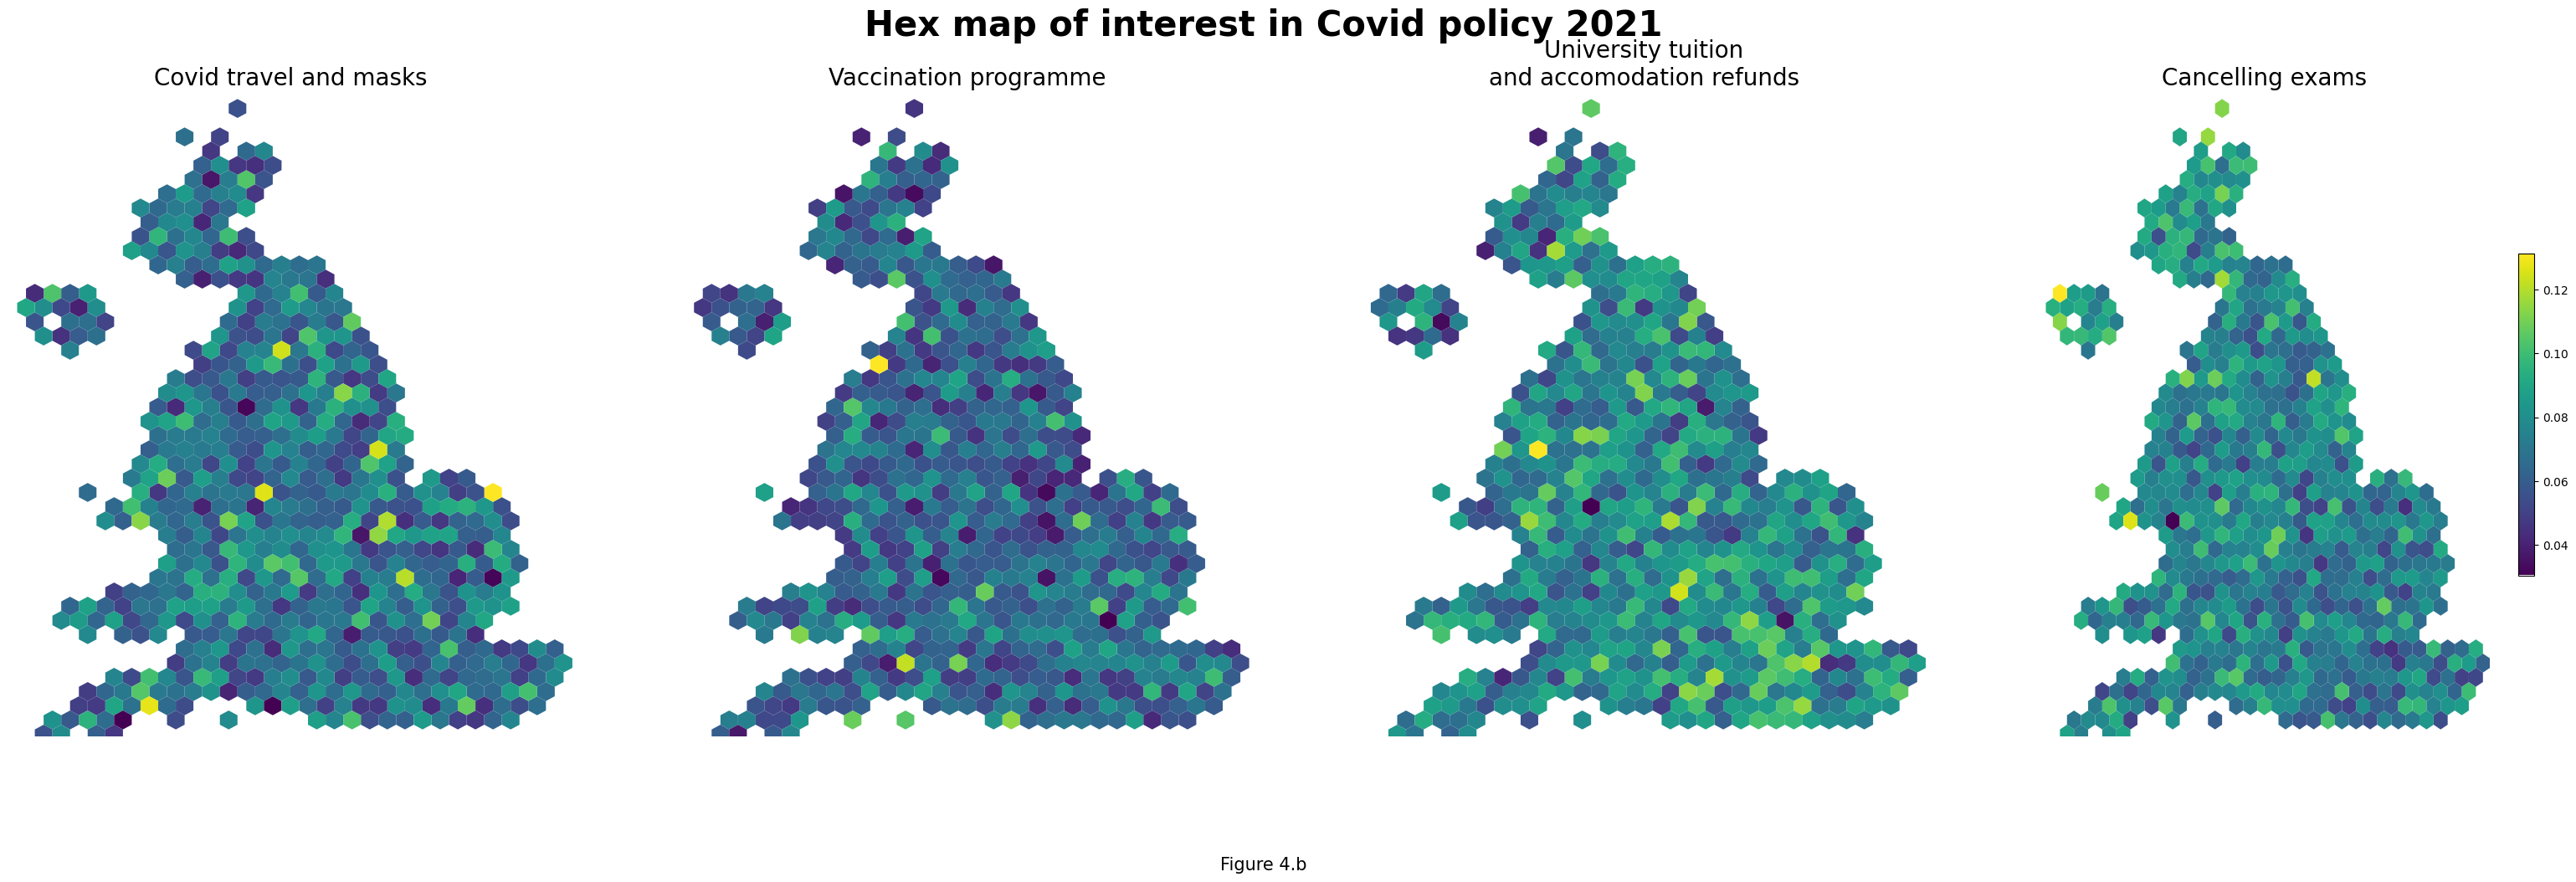

In [24]:
# setting titles
titles = ["Covid travel and masks", "Vaccination programme", "University tuition\nand accomodation refunds", "Cancelling exams"]

# instantiating map
hexmapper = HexMap()
hexmapper.load_map(combined_con_2021, is_path=False, columns_to_plot=["Weighted Topic 10", "Weighted Topic 15", "Weighted Topic 9", "Weighted Topic 2"])

# Draw the map
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in Covid policy 2021", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 4.b", ha="center", fontsize=15)
plt.show()


# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_covid_2021.png", save_dir=save_dir, dpi=300)

In [25]:
con_1 = top_constituencies(petitions_con_2021, "Weighted Topic 10")
con_2 = top_constituencies(petitions_con_2021, "Weighted Topic 15")
con_3 = top_constituencies(petitions_con_2021, "Weighted Topic 9")
con_4 = top_constituencies(petitions_con_2021, "Weighted Topic 2")

print("Top constituencies for each topic: ", con_1, con_2, con_3, con_4)

Top constituencies for each topic:  ['Suffolk Coastal' 'Yeovil' 'Stoke-on-Trent Central' 'Newark'
 'Richmond (Yorks)'] ['Fylde' 'Salisbury' 'Arundel and South Downs' 'Bridgend' 'Aldershot'] ['Warrington North' 'Oxford West and Abingdon' 'Greenwich and Woolwich'
 'North Warwickshire' 'Livingston'] ['Foyle' 'Dwyfor Meirionnydd' 'Leeds East'
 'Dumfriesshire, Clydesdale and Tweeddale'
 'Caithness, Sutherland and Easter Ross']


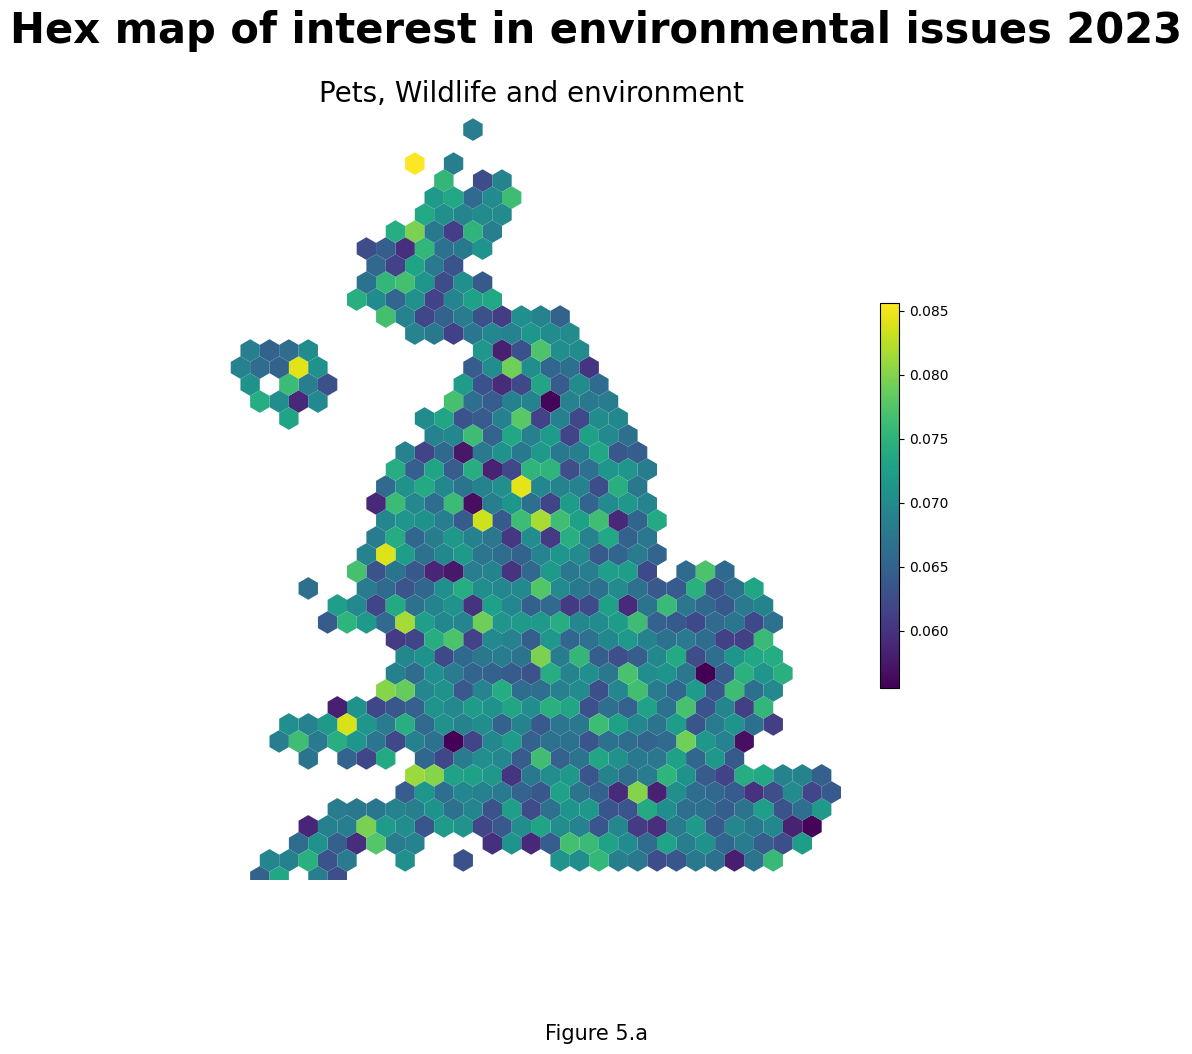

In [26]:
titles =  ["Pets, Wildlife and environment"] 

hexmapper = HexMap()
hexmapper.load_map(combined_con_2023, is_path=False, columns_to_plot=["Weighted Topic 5"])

# Draw the map
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in environmental issues 2023", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 5.a", ha="center", fontsize=15)
plt.show()


# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_env_2023.png", save_dir=save_dir, dpi=300)

In [27]:
con_1 = top_constituencies(petitions_con_2023, "Weighted Topic 5")
print("Top constituencies for each topic: ", con_1)

Top constituencies for each topic:  ['Na h-Eileanan an Iar' 'Huddersfield' 'Belfast North'
 'Liverpool, Wavertree' 'Neath']


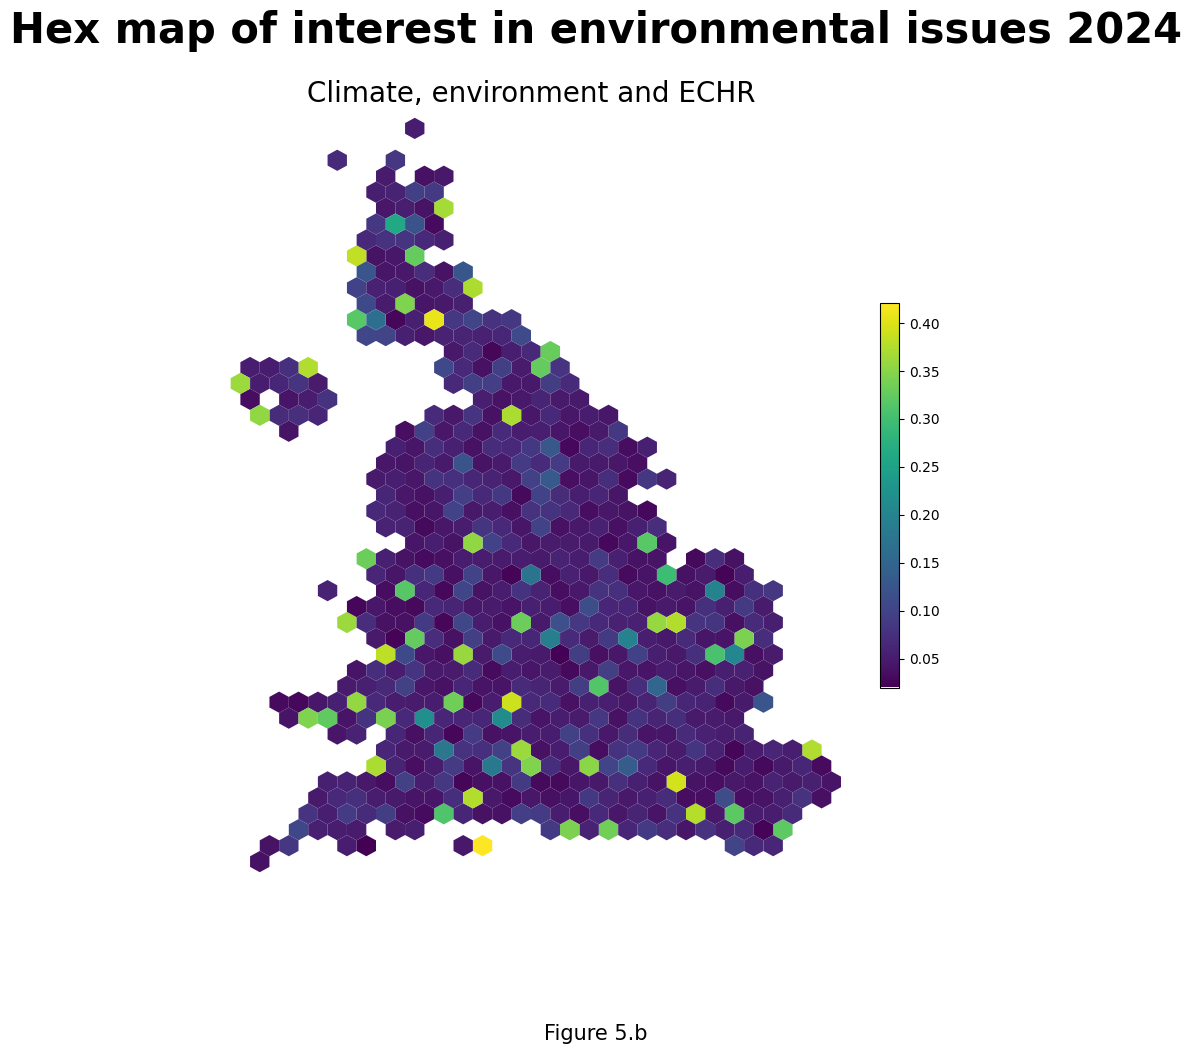

In [28]:
titles =  ["Climate, environment and ECHR"] 

hexmapper = HexMap()
hexmapper.load_map(combined_con_2024, is_path=False, columns_to_plot=["Weighted Topic 16"])

# Draw the map
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in environmental issues 2024", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 5.b", ha="center", fontsize=15)
plt.show()


# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_env_2023.png", save_dir=save_dir, dpi=300)

In [29]:
con_1 = top_constituencies(petitions_con_2024, "Weighted Topic 16")
print("Top constituencies for each topic: ", con_1)

Top constituencies for each topic:  ['Isle of Wight East' 'Motherwell, Wishaw and Carluke' 'Peckham'
 'Earley and Woodley' 'Inverclyde and Renfrewshire West']


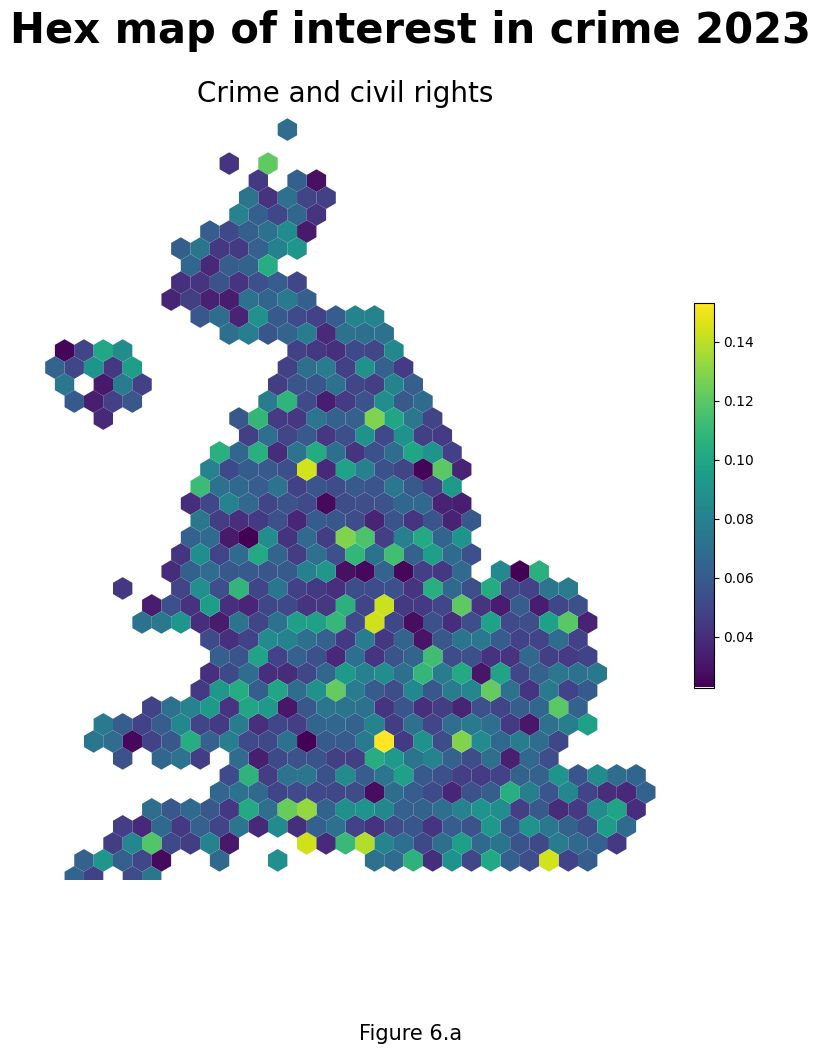

In [30]:
titles =  ["Crime and civil rights"] 

hexmapper = HexMap()
hexmapper.load_map(combined_con_2023, is_path=False, columns_to_plot=["Weighted Topic 2"])

# Draw the map
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in crime 2023", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 6.a", ha="center", fontsize=15)
plt.show()


# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_crime_2023.png", save_dir=save_dir, dpi=300)

In [31]:
con_1 = top_constituencies(petitions_con_2023, "Weighted Topic 2")
print("Top constituencies for each topic: ", con_1)

Top constituencies for each topic:  ['Uxbridge and South Ruislip' 'Rochdale' 'Lewes' 'North Warwickshire'
 'Fareham']


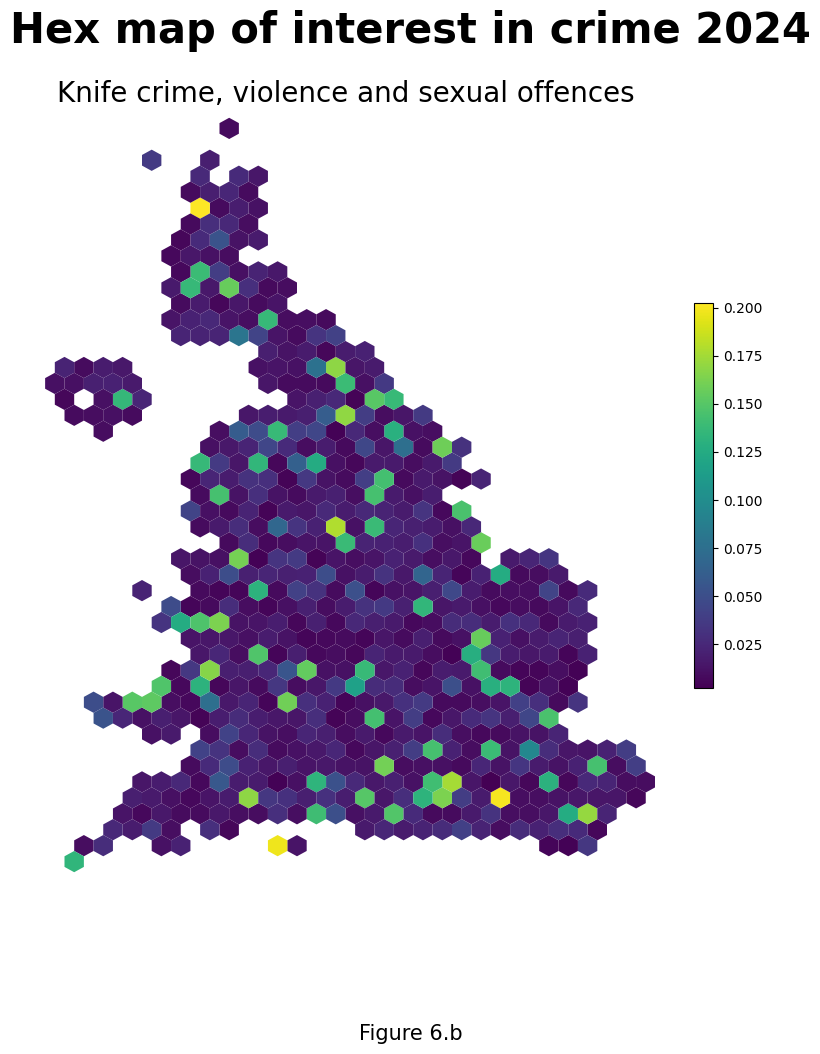

In [32]:
titles =  ["Knife crime, violence and sexual offences"] 

hexmapper = HexMap()
hexmapper.load_map(combined_con_2024, is_path=False, columns_to_plot=["Weighted Topic 11"])

# Draw the map
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in crime 2024", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 6.b", ha="center", fontsize=15)
plt.show()


# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_crime_2024.png", save_dir=save_dir, dpi=300)

In [33]:
con_1 = top_constituencies(petitions_con_2024, "Weighted Topic 11")
print("Top constituencies for each topic: ", con_1)

Top constituencies for each topic:  ['Argyll, Bute and South Lochaber' 'Croydon East' 'Isle of Wight West'
 'High Peak' 'Battersea']


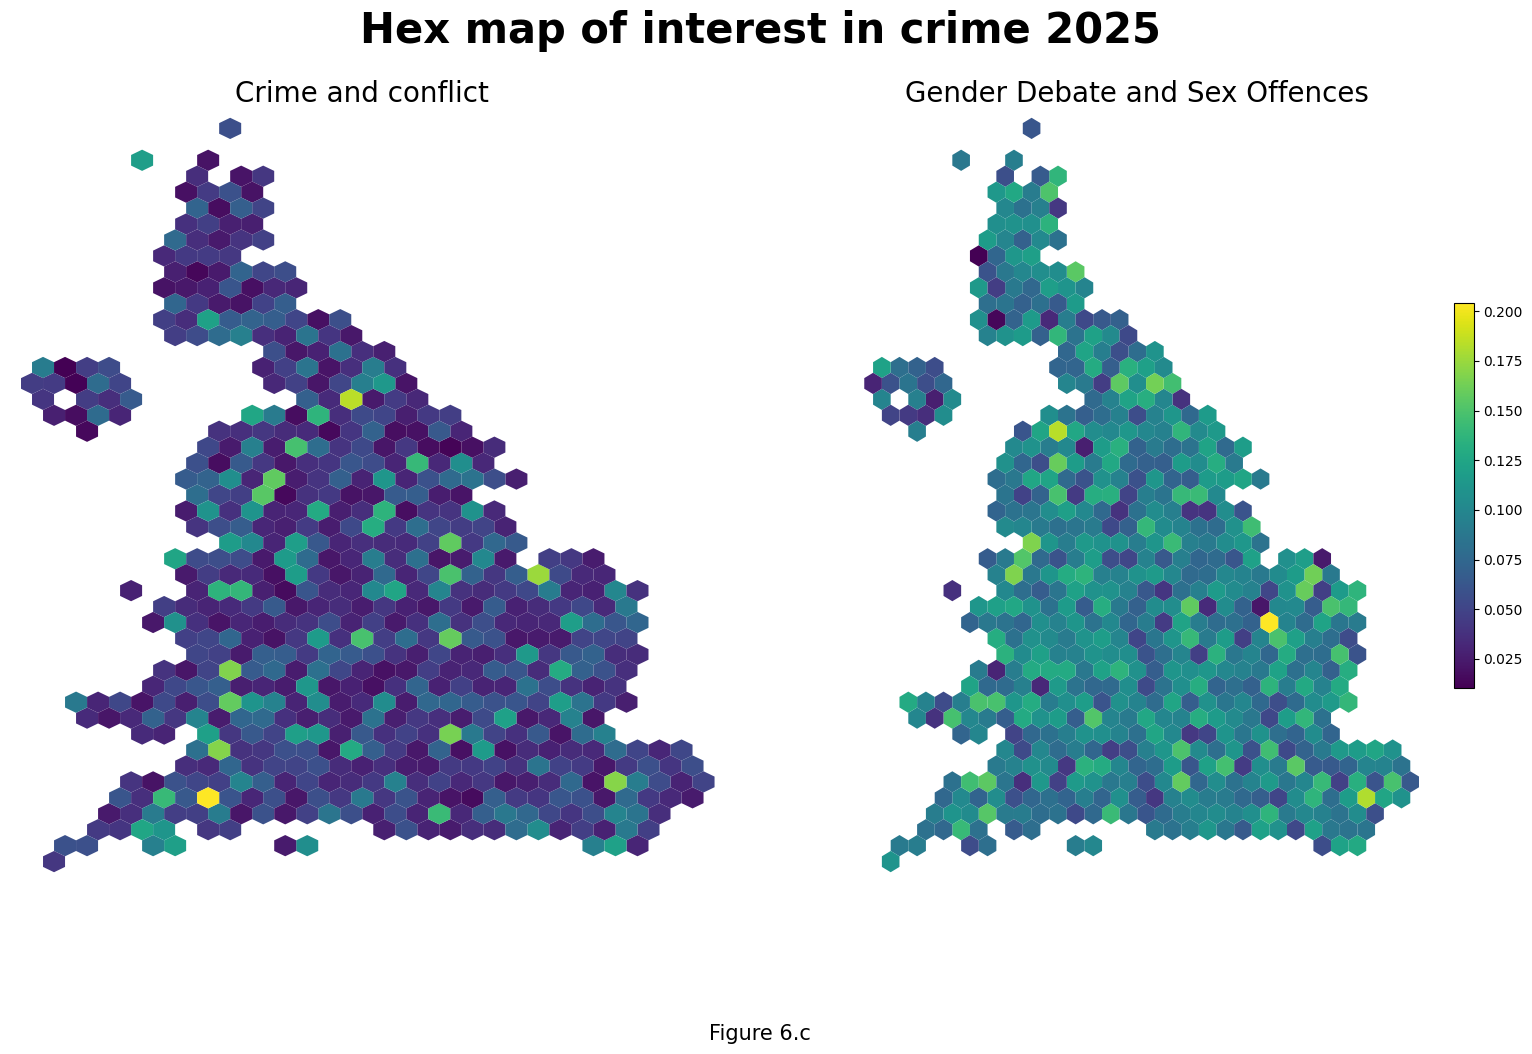

In [34]:
titles =  ["Crime and conflict", "Gender Debate and Sex Offences"] 

hexmapper = HexMap()
hexmapper.load_map(combined_con_2025, is_path=False, columns_to_plot=["Weighted Topic 1", "Weighted Topic 5"])

# Draw the map
title_kwargs = {"fontsize": "20", "fontweight": "6"}

# drawing the map with the titles and font parameter for each subplot
fig = hexmapper.draw_map(
    titles=titles, title_kwargs=title_kwargs
)

# adding broader title for all the subplots
plt.suptitle("Hex map of interest in crime 2025", fontsize=30, fontweight='bold')
plt.figtext(0.5, -0.05, "Figure 6.c", ha="center", fontsize=15)
plt.show()


# Save the map
save_dir = Path("data/maps")
hexmapper.save_map("hexmap_crime_2025.png", save_dir=save_dir, dpi=300)

In [35]:
con_1 = top_constituencies(petitions_con_2025, "Weighted Topic 1")
con_2 = top_constituencies(petitions_con_2025, "Weighted Topic 5")

print("Top constituencies for each topic: ", con_1, con_2)

Top constituencies for each topic:  ['Yeovil' 'Stockton West' 'Mid Norfolk' 'Tonbridge'
 'North East Somerset and Hanham'] ['St Neots and Mid Cambridgeshire' 'Preston' 'Sussex Weald'
 'Widnes and Halewood' 'Chester North and Neston']
